# RankForge · 01 — Data Ingestion Research

**Goal:** Amazon Reviews 2023 ki ek category ko samajhna aur *evidence ke saath* decide karna ki kya ingest karna hai.
Is notebook ke end par do cheezein hongi:

1. **Bronze** — original `.jsonl` files, bilkul untouched (immutable)
2. **Silver** — validated, typed, year-partitioned Parquet (zstd): `interactions` + `products`

**Sawal jinke jawab is notebook ko dene hain** (har ek ka answer neeche Findings mein likhna):

| # | Question | Kyun matter karta hai |
|---|---|---|
| Q1 | Raw records ka exact structure kya hai? Nested fields kaun se hain? | Schema decide karega |
| Q2 | Kitne rows corrupt / null / invalid hain? | Data quality baseline |
| Q3 | Timestamp kis unit mein hai, range kya hai, saal-wise volume kitna hai? | Temporal split + partitioning |
| Q4 | Duplicates kitne hain? `asin` vs `parent_asin` mein kitna farak hai? | Item id choice |
| Q5 | Users/items kitne sparse hain? 1-interaction users kitne %? | k-core decision |
| Q6 | Metadata kitne items cover karta hai? Text fields kitne bhare hain? | Cold-start / text tower feasibility |

## Concepts pehle (3 decisions jo code se pehle samajhne zaroori hain)

**1. Bronze/Silver kyun?** Analogy: Bronze = original receipt ki photocopy, kabhi edit nahi hoti. Silver = us receipt se banayi saaf Excel sheet. Kal agar cleaning logic mein bug nikla, to Bronze se dobara Silver bana sakte ho — source dobara download nahi karna padega.

**2. `.jsonl` kyun, `.jsonl.gz` kyun nahi?** Gzip *splittable nahi* hota. Spark 22 GB ki `.gz` file ko sirf **ek task** mein padhega, baaki cores khaali baithenge. Plain `.jsonl` ko Spark chunks (~128 MB) mein tod ke parallel padhta hai. Hugging Face par files plain `.jsonl` hain — isliye wahi use kar rahe hain.

**3. Explicit schema kyun, `inferSchema` kyun nahi?** Inference ke liye Spark ko poora data ek extra baar scan karna padta hai (22 GB = minutes), aur agar kisi row mein `price` string ho aur kisi mein number, to type har run mein alag aa sakta hai. Explicit schema = fast + deterministic. Jo field type se match na kare, wo `_corrupt_record` mein jaata hai — jise hum count karenge (Q2).

In [1]:
import json, os, shutil
from pathlib import Path

# ---------------- CONFIG ----------------
CATEGORY   = os.environ.get("RANKFORGE_CATEGORY", "Video_Games")   # L1. Baad mein: Movies_and_TV, Electronics
DATA_ROOT  = Path(os.environ.get("RANKFORGE_DATA", "../data")).resolve()
HF_REPO    = "McAuley-Lab/Amazon-Reviews-2023"
DRIVER_MEM = os.environ.get("RANKFORGE_DRIVER_MEM", "8g")          # 16 GB laptop par 8g theek hai

BRONZE_REVIEWS = DATA_ROOT / "bronze" / "reviews"  / f"category={CATEGORY}" / f"{CATEGORY}.jsonl"
BRONZE_META    = DATA_ROOT / "bronze" / "metadata" / f"category={CATEGORY}" / f"meta_{CATEGORY}.jsonl"
SILVER         = DATA_ROOT / "silver"
SILVER_INTER   = SILVER / "interactions" / f"category={CATEGORY}"
SILVER_PROD    = SILVER / "products"     / f"category={CATEGORY}"
print("data root:", DATA_ROOT)

data root: E:\Sheriff_faang\full_end_to_end_project_implementation\RecoSphere\data


## Step 1 — Raw files → Bronze

File pehle se hai to skip. Hugging Face se seedha download (official README ka `load_dataset(..., trust_remote_code=True)` naye `datasets` versions mein fail ho sakta hai — isliye `hf_hub_download`).

In [2]:
def to_bronze(repo_path: str, target: Path):
    if target.exists():
        print(f"exists, skip: {target.name}  ({target.stat().st_size / 1e9:.2f} GB)")
        return
    from huggingface_hub import hf_hub_download
    target.parent.mkdir(parents=True, exist_ok=True)
    tmp = target.parent / "_dl"
    local = hf_hub_download(HF_REPO, repo_path, repo_type="dataset", local_dir=tmp)
    os.replace(local, target)          # move, copy nahi -> disk double nahi hoti
    shutil.rmtree(tmp, ignore_errors=True)
    print(f"downloaded: {target.name}  ({target.stat().st_size / 1e9:.2f} GB)")

to_bronze(f"raw/review_categories/{CATEGORY}.jsonl", BRONZE_REVIEWS)
to_bronze(f"raw/meta_categories/meta_{CATEGORY}.jsonl", BRONZE_META)

e:\Sheriff_faang\full_end_to_end_project_implementation\RecoSphere\.reco\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


downloaded: Video_Games.jsonl  (2.68 GB)
downloaded: meta_Video_Games.jsonl  (0.44 GB)


## Step 2 — Q1: Raw record ko aankh se dekho (Spark se pehle)

Sirf pehli 2 lines, plain Python. 20 GB file ko pandas mein load karne ki galti mat karna.

In [3]:
def peek(path: Path, n=2, max_str=120):
    with open(path) as f:
        for _, line in zip(range(n), f):
            rec = json.loads(line)
            short = {k: (v[:max_str] + "…" if isinstance(v, str) and len(v) > max_str else v) for k, v in rec.items()}
            print(json.dumps(short, indent=2, default=str)[:2500]); print("-" * 60)
            print({k: type(v).__name__ for k, v in rec.items()}); print("=" * 60)

peek(BRONZE_REVIEWS)

{
  "rating": 4.0,
  "title": "It\u2019s pretty sexual. Not my fav",
  "text": "I\u2019m playing on ps5 and it\u2019s interesting.  It\u2019s unique, massive, and has a neat story.  People are freaking out angry abo\u2026",
  "images": [],
  "asin": "B07DJWBYKP",
  "parent_asin": "B07DK1H3H5",
  "user_id": "AGCI7FAH4GL5FI65HYLKWTMFZ2CQ",
  "timestamp": 1608186804795,
  "helpful_vote": 0,
  "verified_purchase": true
}
------------------------------------------------------------
{'rating': 'float', 'title': 'str', 'text': 'str', 'images': 'list', 'asin': 'str', 'parent_asin': 'str', 'user_id': 'str', 'timestamp': 'int', 'helpful_vote': 'int', 'verified_purchase': 'bool'}
{
  "rating": 5.0,
  "title": "Good. A bit slow",
  "text": "Nostalgic fun.  A bit slow.  I hope they don\u2019t stretch it out too far.  It\u2019s good tho",
  "images": [],
  "asin": "B00ZS80PC2",
  "parent_asin": "B07SRWRH5D",
  "user_id": "AGCI7FAH4GL5FI65HYLKWTMFZ2CQ",
  "timestamp": 1587051114941,
  "helpful_vote":

In [4]:
peek(BRONZE_META, n=1)

{
  "main_category": "Video Games",
  "title": "Dash 8-300 Professional Add-On",
  "average_rating": 5.0,
  "rating_number": 1,
  "features": [
    "Features Dash 8-300 and 8-Q300 ('Q' rollout livery)",
    "Airlines - US Airways, South African Express, Bahamasair, Augsburg Airways, Lufthansa Cityline, British Airways (Union Jack), British European, FlyBe, Intersky, Wideroe, Iberia, Tyrolean, QantasLink, BWIA",
    "Airports include - London City, Frankfurt, Milan and Amsterdam Schipol",
    "Includes PSS PanelConfig and LoadEdit tools"
  ],
  "description": [
    "The Dash 8-300 Professional Add-On lets you pilot a real commuter special. Fly two versions of the popular Dash 8-300 in a total of 17 different liveries. The Dash 8-300 is one of the most popular short-haul aircraft available and this superbly modelled version from acclaimed aircraft developers PSS is modelled in two versions with a total of 17 different liveries. The package also includes scenery for three European airport

**Dekhne layak cheezein:** `timestamp` mein kitne digits hain (13 = milliseconds)? `images` list of objects hai. Metadata mein `details` ek dict hai jiski keys har item mein alag hain, aur `price` kabhi number, kabhi `"None"` string hota hai. Ye sab schema decisions ko drive karta hai.

## Step 3 — Spark session (local mode)

`local[*]` = laptop ke saare cores. Same code baad mein EMR par chalega; sirf master aur paths (`s3a://...`) badlenge.

In [1]:
import os, shutil
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))
print("java on PATH:", shutil.which("java"))

JAVA_HOME: None
java on PATH: None


In [3]:
import os, sys
from pathlib import Path
os.environ["JAVA_HOME"] = r"C:\Program Files\Eclipse Adoptium\jdk-21.0.13.9-hotspot"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Windows par Spark ko local disk par likhne ke liye winutils.exe + hadoop.dll chahiye
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]
missing = [f for f in ("winutils.exe", "hadoop.dll") if not (Path(os.environ["HADOOP_HOME"]) / "bin" / f).exists()]
assert not missing, f"C:\\hadoop\\bin mein missing: {missing}"

In [4]:
from pyspark.sql import SparkSession, functions as F, types as T

spark = (SparkSession.builder
         .master("local[*]")
         .appName(f"rankforge-ingest-{CATEGORY}")
         .config("spark.driver.memory", DRIVER_MEM)
         .config("spark.sql.session.timeZone", "UTC")          # timestamps ka timezone fix
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.sql.parquet.compression.codec", "zstd")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
spark.version

'4.3.0'

## Step 4 — Reviews: explicit schema ke saath read

Nested `images` ko `StringType` diya hai — Spark object ko raw JSON text ki tarah rakh deta hai. Silver mein images chahiye nahi, sirf "image tha ya nahi" count karna hai.

In [5]:
REVIEW_SCHEMA = T.StructType([
    T.StructField("rating",            T.DoubleType()),
    T.StructField("title",             T.StringType()),
    T.StructField("text",              T.StringType()),
    T.StructField("images",            T.StringType()),
    T.StructField("asin",              T.StringType()),
    T.StructField("parent_asin",       T.StringType()),
    T.StructField("user_id",           T.StringType()),
    T.StructField("timestamp",         T.LongType()),
    T.StructField("helpful_vote",      T.LongType()),
    T.StructField("verified_purchase", T.BooleanType()),
    T.StructField("_corrupt_record",   T.StringType()),
])

reviews_raw = (spark.read
               .schema(REVIEW_SCHEMA)
               .option("mode", "PERMISSIVE")
               .option("columnNameOfCorruptRecord", "_corrupt_record")
               .json(str(BRONZE_REVIEWS))
               .cache())          # profiling mein baar-baar padhenge
n_raw = reviews_raw.count()
print(f"rows: {n_raw:,}   input partitions: {reviews_raw.rdd.getNumPartitions()}")

rows: 4,624,615   input partitions: 32


## Step 5 — Q2: Data quality — corrupt rows, nulls, invalid values

In [6]:
n_corrupt = reviews_raw.filter(F.col("_corrupt_record").isNotNull()).count()

valid_raw = reviews_raw.filter(F.col("_corrupt_record").isNull())   # corrupt rows alag gine gaye hain
null_counts = valid_raw.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in ["user_id", "parent_asin", "asin", "rating", "timestamp", "verified_purchase"]
]).first().asDict()

invalid = valid_raw.select(
    F.sum((~F.col("rating").between(1, 5)).cast("int")).alias("rating_out_of_range"),
    F.sum((F.col("timestamp") <= 0).cast("int")).alias("non_positive_ts"),
    F.sum((F.trim(F.coalesce("text", F.lit(""))) == "").cast("int")).alias("empty_text"),
).first().asDict()

print(f"corrupt rows: {n_corrupt:,} ({n_corrupt / n_raw:.4%})")
print("nulls:", null_counts)
print("invalid:", invalid)

corrupt rows: 0 (0.0000%)
nulls: {'user_id': 0, 'parent_asin': 0, 'asin': 0, 'rating': 0, 'timestamp': 0, 'verified_purchase': 0}
invalid: {'rating_out_of_range': 0, 'non_positive_ts': 0, 'empty_text': 3618}


## Step 6 — Q3: Timestamp unit, range, saal-wise volume

In [7]:
ts_stats = reviews_raw.select(
    F.min("timestamp").alias("min"), F.max("timestamp").alias("max"),
    F.expr("percentile_approx(length(cast(timestamp as string)), 0.5)").alias("median_digits"),
).first()
print(ts_stats)
TS_IS_MS = ts_stats["median_digits"] >= 13
print("timestamp unit:", "milliseconds" if TS_IS_MS else "seconds")

ts_sec = (F.col("timestamp") / 1000).cast("long") if TS_IS_MS else F.col("timestamp")
reviews = (reviews_raw
           .filter(F.col("_corrupt_record").isNull())
           .withColumn("ts", ts_sec)
           .withColumn("event_ts", F.col("ts").cast("timestamp"))
           .withColumn("event_year", F.year("event_ts")))

by_year = reviews.groupBy("event_year").count().orderBy("event_year").toPandas()
by_year["share"] = (by_year["count"] / by_year["count"].sum()).round(4)
by_year

Row(min=911332729000, max=1694509355529, median_digits=13)
timestamp unit: milliseconds


,event_year,count,share
0,1998,6,0.0000
1,1999,458,0.0001
2,2000,4825,0.0010
3,2001,10832,0.0023
4,2002,14349,0.0031
5,2003,14130,0.0031
6,2004,15269,0.0033
7,2005,16678,0.0036
8,2006,16467,0.0036
9,2007,28768,0.0062


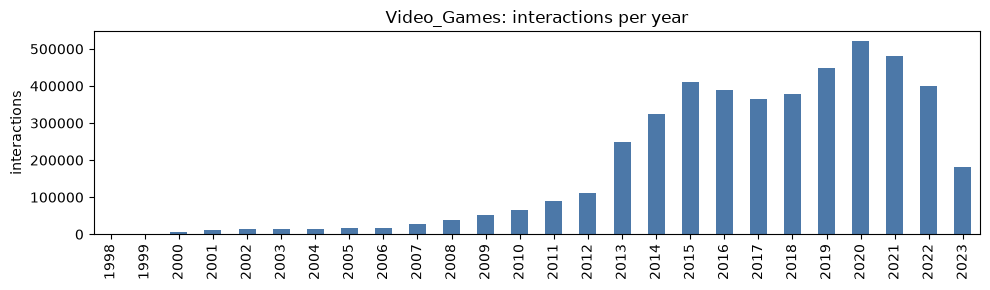

In [8]:
import matplotlib.pyplot as plt
ax = by_year.plot.bar(x="event_year", y="count", legend=False, figsize=(10, 3), color="#4C78A8")
ax.set_title(f"{CATEGORY}: interactions per year"); ax.set_ylabel("interactions"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Iska matlab:** agar shuru ke saalon mein bahut kam rows hain, to `event_year` partitioning se *small files problem* aata hai (bahut saari chhoti files = Spark ke liye slow). Isliye silver write mein per-partition files control karenge. Saath hi, temporal split ke cutoffs isi distribution se aate hain — "last 30 days" agar 0.5% data hai to test set bahut chhota hoga.

## Step 7 — Q4: Duplicates aur `asin` vs `parent_asin`

In [9]:
dup = reviews.select(
    F.count("*").alias("rows"),
    F.countDistinct("user_id", "parent_asin").alias("distinct_user_parent"),
    F.countDistinct("user_id", "asin", "timestamp").alias("distinct_exact"),
    F.countDistinct("asin").alias("asins"),
    F.countDistinct("parent_asin").alias("parent_asins"),
    F.countDistinct("user_id").alias("users"),
).first().asDict()

dup["exact_dup_rows"]      = dup["rows"] - dup["distinct_exact"]
dup["repeat_user_item_%"]  = round(100 * (1 - dup["distinct_user_parent"] / dup["rows"]), 3)
dup["asin_per_parent"]     = round(dup["asins"] / dup["parent_asins"], 3)
dup

{'rows': 4624615,
 'distinct_user_parent': 4555500,
 'distinct_exact': 4570967,
 'asins': 167645,
 'parent_asins': 137249,
 'users': 2766656,
 'exact_dup_rows': 53648,
 'repeat_user_item_%': 1.495,
 'asin_per_parent': 1.221}

**Do alag cheezein, do alag decisions:**
- *Exact duplicates* (same user, asin, timestamp) = ingestion artefact → **Silver mein hatao**.
- *Repeat (user, parent_asin)* = user ne same product family ko dobara review kiya → ye **modeling decision** hai (implicit feedback mein ek signal), isliye Silver mein rakho, `prepare` step mein dedup karo. Silver ko modeling assumptions se saaf rakhna hai.

## Step 8 — Q5: Sparsity — users aur items kitne thin hain

In [10]:
def activity(col):
    per = reviews.groupBy(col).count()
    buckets = (per.withColumn("bucket", F.when(F.col("count") == 1, "1")
                                        .when(F.col("count") < 5, "2-4")
                                        .when(F.col("count") < 20, "5-19")
                                        .otherwise("20+"))
                  .groupBy("bucket").agg(F.count("*").alias(f"n_{col}"), F.sum("count").alias("interactions"))
                  .toPandas().set_index("bucket").loc[["1", "2-4", "5-19", "20+"]])
    buckets[f"%_{col}"] = (100 * buckets[f"n_{col}"] / buckets[f"n_{col}"].sum()).round(2)
    buckets["%_interactions"] = (100 * buckets["interactions"] / buckets["interactions"].sum()).round(2)
    return buckets

print("USERS"); display(activity("user_id"))
print("ITEMS (parent_asin)"); display(activity("parent_asin"))

USERS


,n_user_id,interactions,%_user_id,%_interactions
bucket,,,,
1,1997753,1997753,72.21,43.20
2-4,651161,1596333,23.54,34.52
5-19,112022,834812,4.05,18.05
20+,5720,195717,0.21,4.23


ITEMS (parent_asin)


,n_parent_asin,interactions,%_parent_asin,%_interactions
bucket,,,,
1,37839,37839,27.57,0.82
2-4,36230,98728,26.40,2.13
5-19,35844,346883,26.12,7.50
20+,27336,4141165,19.92,89.55


**k-core ka intuition:** `5-19` aur `20+` buckets dikhate hain ki 5-core ke baad roughly kitna data bachega (exact number iterative filter ke baad aayega, kyunki users hatane se items bhi girte hain). Agar 1-interaction users ka share bahut high hai, to ye data "personalization" ke liye kuch nahi deta — unke liye popularity hi best hai.

## Step 9 — Metadata: Q6 coverage aur text quality

`price` ko string padh rahe hain (kyunki raw mein `"None"` aata hai) aur baad mein safe cast. `details` ka dict har item mein alag hai → raw JSON string rakho, zaroorat padne par `from_json`.

In [11]:
META_SCHEMA = T.StructType([
    T.StructField("main_category",   T.StringType()),
    T.StructField("title",           T.StringType()),
    T.StructField("average_rating",  T.DoubleType()),
    T.StructField("rating_number",   T.LongType()),
    T.StructField("features",        T.ArrayType(T.StringType())),
    T.StructField("description",     T.ArrayType(T.StringType())),
    T.StructField("price",           T.StringType()),
    T.StructField("images",          T.StringType()),
    T.StructField("videos",          T.StringType()),
    T.StructField("store",           T.StringType()),
    T.StructField("categories",      T.ArrayType(T.StringType())),
    T.StructField("details",         T.StringType()),
    T.StructField("parent_asin",     T.StringType()),
    T.StructField("bought_together", T.StringType()),
    T.StructField("_corrupt_record", T.StringType()),
])
meta_raw = (spark.read.schema(META_SCHEMA).option("mode", "PERMISSIVE")
            .option("columnNameOfCorruptRecord", "_corrupt_record")
            .json(str(BRONZE_META)).cache())

empty_arr = lambda c: (F.coalesce(F.size(c), F.lit(0)) <= 0)
blank     = lambda c: (F.trim(F.coalesce(F.col(c), F.lit(""))) == "")
meta_q = meta_raw.select(
    F.count("*").alias("rows"),
    F.countDistinct("parent_asin").alias("distinct_items"),
    F.sum(F.col("_corrupt_record").isNotNull().cast("int")).alias("corrupt"),
    F.avg(blank("title").cast("int")).alias("title_blank_%"),
    F.avg(empty_arr("description").cast("int")).alias("description_empty_%"),
    F.avg(empty_arr("features").cast("int")).alias("features_empty_%"),
    F.avg(empty_arr("categories").cast("int")).alias("categories_empty_%"),
    F.avg(blank("store").cast("int")).alias("store_blank_%"),
    F.avg(F.expr("try_cast(price as double)").isNotNull().cast("int")).alias("price_parsable_%"),
).first().asDict()
{k: (round(100 * v, 2) if k.endswith("%") else v) for k, v in meta_q.items()}

{'rows': 137269,
 'distinct_items': 137269,
 'corrupt': 0,
 'title_blank_%': 0.01,
 'description_empty_%': 37.69,
 'features_empty_%': 28.77,
 'categories_empty_%': 9.21,
 'store_blank_%': 3.18,
 'price_parsable_%': 45.15}

In [12]:
# Coverage: kitne interacted items ke paas metadata hai, aur wo kitne % interactions cover karte hain
meta_items = meta_raw.select("parent_asin").distinct().withColumn("has_meta", F.lit(1))
cov = (reviews.groupBy("parent_asin").count()
       .join(meta_items, "parent_asin", "left")
       .select(F.avg(F.col("has_meta").isNotNull().cast("int")).alias("items_with_meta_%"),
               (F.sum(F.when(F.col("has_meta").isNotNull(), F.col("count"))) / F.sum("count")).alias("interactions_covered_%"))
       .first().asDict())
{k: round(100 * v, 2) for k, v in cov.items()}

{'items_with_meta_%': 100.0, 'interactions_covered_%': 100.0}

In [13]:
# details ki sabse common keys -> kaun se structured attributes features ban sakte hain
details_keys = (meta_raw
    .select(F.explode(F.map_keys(F.from_json("details", T.MapType(T.StringType(), T.StringType())))).alias("key"))
    .groupBy("key").count().orderBy(F.desc("count")).limit(15).toPandas())
details_keys["%_items"] = (100 * details_keys["count"] / meta_q["rows"]).round(1)
details_keys

,key,count,%_items
0,Date First Available,128499,93.6
1,Manufacturer,115433,84.1
2,Item Weight,110232,80.3
3,Pricing,83932,61.1
4,Best Sellers Rank,75847,55.3
5,Type of item,75437,55.0
6,Is Discontinued By Manufacturer,65753,47.9
7,Item model number,59269,43.2
8,Product Dimensions,59175,43.1
9,Package Dimensions,52439,38.2


## Step 10 — Ingestion decision table

Upar ke numbers ke basis par. **Proposal** pre-filled hai — apne real numbers dekh ke "Why" column update karna.

**Silver `interactions`**

| Column | Keep? | Why |
|---|---|---|
| `user_id`, `parent_asin` → `item_id` | ✅ | Core interaction key; metadata join `parent_asin` par |
| `asin` | ✅ | Variant-level analysis ke liye sasta hai; modeling `item_id` par |
| `rating` | ✅ | Label nahi (implicit feedback), lekin feature/filter ke liye |
| `ts` (seconds), `event_ts`, `event_year` | ✅ | Split + partitioning |
| `verified_purchase`, `helpful_vote` | ✅ | Signal-quality features |
| `has_image` | ✅ (derived) | Sasta engagement proxy |
| `text`, `title` (review) | ❌ | Sabse heavy columns; abhi kisi model ko nahi chahiye. Bronze mein safe hain |
| `images` (raw) | ❌ | URLs, modeling value nahi |

**Silver `products`**

| Column | Keep? | Why |
|---|---|---|
| `parent_asin` → `item_id`, `title`, `features`, `description`, `categories` | ✅ | Item tower text + cold start |
| `store`, `main_category`, `price` (double), `average_rating`, `rating_number` | ✅ | Ranker features |
| `details` (raw JSON) | ✅ | Gold mein selected keys nikaalenge |
| `images`, `videos` | ❌ | Abhi multimodal scope mein nahi |
| `bought_together` | check | Agar mostly null nikla to drop |

## Step 11 — Silver write

In [14]:
silver_inter = (reviews
    .dropDuplicates(["user_id", "asin", "timestamp"])            # sirf EXACT duplicates
    .filter(F.col("user_id").isNotNull() & F.col("parent_asin").isNotNull() & F.col("ts").isNotNull())
    .select(
        "user_id",
        F.col("parent_asin").alias("item_id"),
        "asin",
        F.col("rating").cast("float"),
        "ts", "event_ts", "event_year",
        F.col("verified_purchase").alias("verified"),
        F.col("helpful_vote").cast("int"),
        (F.coalesce(F.col("images"), F.lit("[]")) != "[]").alias("has_image"),
    ))

(silver_inter
    .repartition("event_year")                                   # ek saal = ek task -> small files kam
    .write.mode("overwrite")
    .option("maxRecordsPerFile", 5_000_000)                       # bade saal ko split karo
    .partitionBy("event_year")
    .parquet(str(SILVER_INTER)))

silver_prod = (meta_raw
    .filter(F.col("_corrupt_record").isNull() & F.col("parent_asin").isNotNull())
    .dropDuplicates(["parent_asin"])
    .select(
        F.col("parent_asin").alias("item_id"),
        "title", "main_category", "store",
        F.expr("try_cast(price as double)").alias("price"),
        "average_rating", F.col("rating_number").cast("int"),
        "features", "description", "categories", "details",
    ))
silver_prod.coalesce(8).write.mode("overwrite").parquet(str(SILVER_PROD))
print("silver written")

silver written


## Step 12 — Validation: read back, counts match, files sane

In [15]:
si = spark.read.parquet(str(SILVER_INTER))
sp_ = spark.read.parquet(str(SILVER_PROD))
n_si, n_sp = si.count(), sp_.count()
n_valid = reviews.filter(F.col("user_id").isNotNull() & F.col("parent_asin").isNotNull()).count()
exact_dups = dup["exact_dup_rows"]

print(f"bronze rows {n_raw:,} -> corrupt {n_corrupt:,} -> exact dups {exact_dups:,} -> silver {n_si:,}")
assert n_si <= n_valid, "silver mein bronze se zyada rows? join/explode bug"
assert si.filter(F.col("ts").isNull()).count() == 0

def dir_stats(p: Path):
    files = list(p.rglob("*.parquet"))
    return len(files), sum(f.stat().st_size for f in files) / 1e9

for name, p in [("bronze reviews", BRONZE_REVIEWS), ("bronze meta", BRONZE_META)]:
    print(f"{name:<16} {p.stat().st_size / 1e9:7.3f} GB")
for name, p in [("silver inter", SILVER_INTER), ("silver products", SILVER_PROD)]:
    n, gb = dir_stats(p); print(f"{name:<16} {gb:7.3f} GB in {n} files")
si.printSchema()

bronze rows 4,624,615 -> corrupt 0 -> exact dups 53,648 -> silver 4,570,967
bronze reviews     2.683 GB
bronze meta        0.437 GB
silver inter       0.152 GB in 26 files
silver products    0.063 GB in 8 files
root
 |-- user_id: string (nullable = true)
 |-- item_id: string (nullable = true)
 |-- asin: string (nullable = true)
 |-- rating: float (nullable = true)
 |-- ts: long (nullable = true)
 |-- event_ts: timestamp (nullable = true)
 |-- verified: boolean (nullable = true)
 |-- helpful_vote: integer (nullable = true)
 |-- has_image: boolean (nullable = true)
 |-- event_year: integer (nullable = true)



In [16]:
# Ingestion report -> REPORT.md ke liye machine-readable record
report = {
    "category": CATEGORY, "bronze_rows": n_raw, "corrupt_rows": n_corrupt,
    "exact_duplicate_rows": exact_dups, "silver_interactions": n_si, "silver_products": n_sp,
    "users": dup["users"], "items_parent_asin": dup["parent_asins"], "asins": dup["asins"],
    "timestamp_unit": "ms" if TS_IS_MS else "s",
    "first_ts": str(si.agg(F.min("event_ts")).first()[0]), "last_ts": str(si.agg(F.max("event_ts")).first()[0]),
    "repeat_user_item_pct": dup["repeat_user_item_%"],
    "meta_quality": {k: (round(100 * v, 2) if k.endswith("%") else v) for k, v in meta_q.items()},
    "meta_coverage": {k: round(100 * v, 2) for k, v in cov.items()},
}
out = SILVER / f"_ingest_report_{CATEGORY}.json"
out.write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))

{
  "category": "Video_Games",
  "bronze_rows": 4624615,
  "corrupt_rows": 0,
  "exact_duplicate_rows": 53648,
  "silver_interactions": 4570967,
  "silver_products": 137269,
  "users": 2766656,
  "items_parent_asin": 137249,
  "asins": 167645,
  "timestamp_unit": "ms",
  "first_ts": "1998-11-18 01:28:49",
  "last_ts": "2023-09-12 14:32:35",
  "repeat_user_item_pct": 1.495,
  "meta_quality": {
    "rows": 137269,
    "distinct_items": 137269,
    "corrupt": 0,
    "title_blank_%": 0.01,
    "description_empty_%": 37.69,
    "features_empty_%": 28.77,
    "categories_empty_%": 9.21,
    "store_blank_%": 3.18,
    "price_parsable_%": 45.15
  },
  "meta_coverage": {
    "items_with_meta_%": 100.0,
    "interactions_covered_%": 100.0
  }
}


## Findings (REPORT.md mein copy karo — apne real numbers ke saath)

- **Q1 Schema:** …
- **Q2 Quality:** corrupt = …, nulls = …, empty review text = …
- **Q3 Time:** unit = …, range = … → …; last 2 saal = …% of data → split cutoffs ka implication: …
- **Q4 Duplicates:** exact = …, repeat (user, item) = …%, asin/parent = … → item id = `parent_asin` kyunki …
- **Q5 Sparsity:** 1-interaction users = …% (… % of interactions) → k-core choice: …
- **Q6 Metadata:** coverage = …% items / …% interactions; description empty = …% → text tower ke liye input = title + features + …
- **Storage:** bronze … GB → silver … GB (… x compression), kyunki text drop + Parquet/zstd

**Next notebook:** `02_prepare_and_split` — Silver se k-core + temporal split, PySpark mein.

In [17]:
spark.stop()

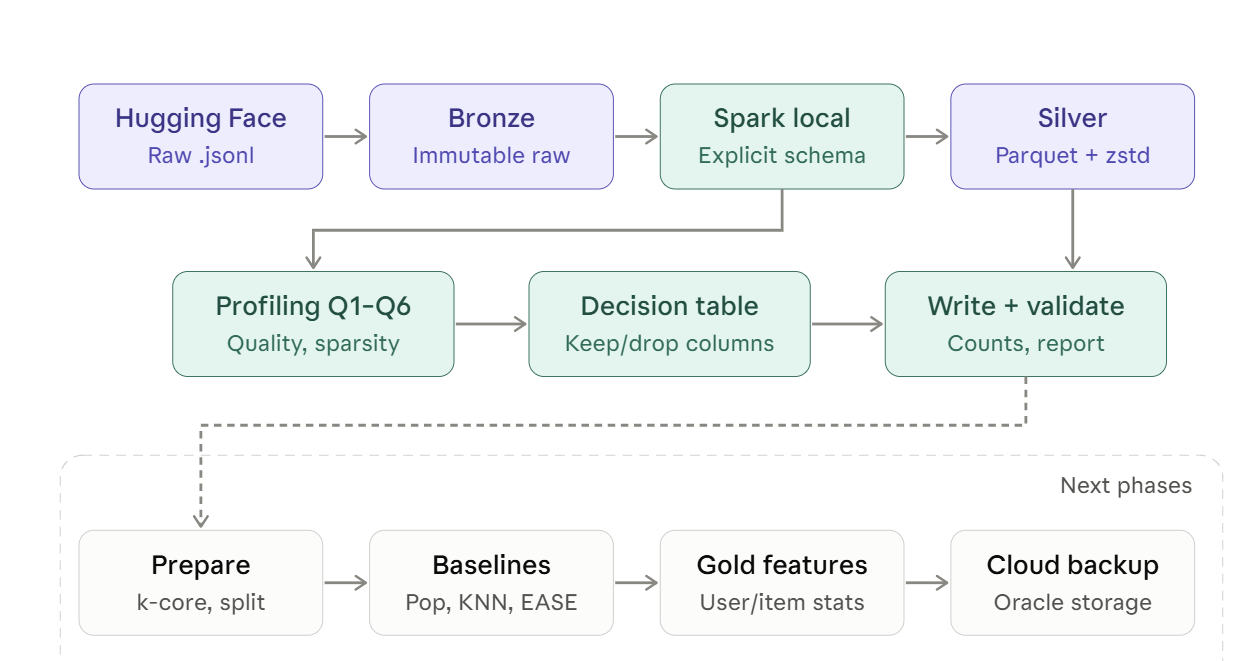